In [121]:
import pandas as pd

df = pd.read_csv('bank_transactions_data_2.csv')
print("Shape:", df.shape)
print(df.columns)
df.head()

Shape: (2512, 16)
Index(['TransactionID', 'AccountID', 'TransactionAmount', 'TransactionDate',
       'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID',
       'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration',
       'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate'],
      dtype='object')


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


# Bank Transaction Analysis & Anomaly Detection
This project analyses the Bank Transaction Dataset for Fraud Detection from Kaggle. It contains 2,512 transactions from 495 accounts, recorded between 2 January 2023 and 1 January 2024. The dataset does not include fraud labels, so it is not possible to confirm whether a transaction is fraudulent. Instead, the analysis focuses on normal transaction patterns and looks for unusual activity that may be suspicious. The analysis uses Python, Pandas, Seaborn and Matplotlib and tries to answer these questions:
1. What is a normal transaction amount and frequency?
2. Which accounts have unusually high activity?
3. Are there transaction bursts within short periods?
4. Are particular times, channels or transaction types unusual?
5. Which variables could be useful for detecting unusual behaviour?
6. Can simple rules flag suspicious transactions?

# Data checking

In [122]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

In [123]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [124]:
import pandas as pd
import matplotlib.pyplot as plt

# Normal Transaction Behaviour

In [125]:
df["TransactionAmount"].describe()

count    2512.000000
mean      297.593778
std       291.946243
min         0.260000
25%        81.885000
50%       211.140000
75%       414.527500
max      1919.110000
Name: TransactionAmount, dtype: float64

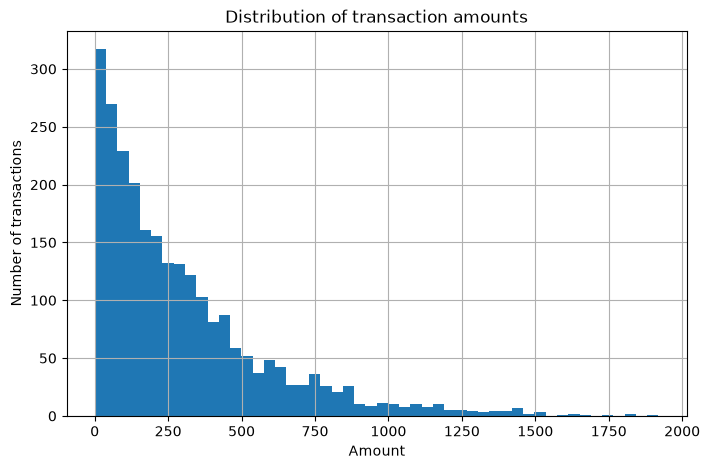

In [126]:
df["TransactionAmount"].hist(bins=50, figsize=(8, 5))
plt.title("Distribution of transaction amounts")
plt.xlabel("Amount")
plt.ylabel("Number of transactions")
plt.show()

The median transaction amount is 211.14, and the middle 50% of transactions range from 81.89 to 414.53. The mean (297.59) is higher than the median because a few large transactions pull the average up. Most transactions  have small amounts, while a few reach up to 1,919.11, which is about nine times the median.

In [127]:
transactions_per_account = df.groupby("AccountID")["TransactionID"].count()
transactions_per_account.describe()

count    495.000000
mean       5.074747
std        2.294261
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: TransactionID, dtype: float64

Most accounts made between 3 and 7 transactions during the year, with a median of 5 transactions per account. This is taken as the normal activity level in the dataset.

# Account Activity

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [129]:
transactions_per_account.sort_values(ascending=False).head(10)

AccountID
AC00362    12
AC00363    12
AC00202    12
AC00460    12
AC00225    11
AC00480    11
AC00304    11
AC00456    11
AC00257    11
AC00219    10
Name: TransactionID, dtype: int64

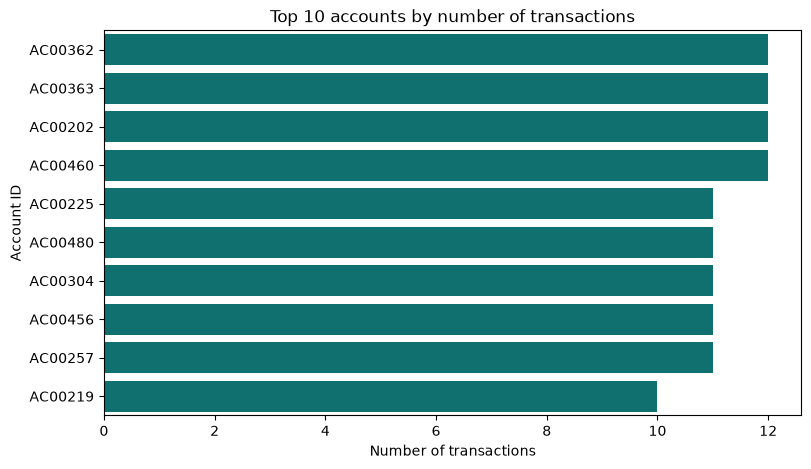

In [130]:
top_accounts = transactions_per_account.sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_accounts.values, y=top_accounts.index, color="teal")
plt.title("Top 10 accounts by number of transactions")
plt.xlabel("Number of transactions")
plt.ylabel("Account ID")
plt.show()

In [131]:
amount_per_account = df.groupby("AccountID")["TransactionAmount"].sum()
amount_per_account.sort_values(ascending=False).head(10)

AccountID
AC00460    5570.34
AC00363    4702.91
AC00337    4393.41
AC00021    4263.34
AC00439    4185.81
AC00385    4141.20
AC00071    4050.12
AC00265    3953.60
AC00136    3880.53
AC00179    3819.73
Name: TransactionAmount, dtype: float64

In [132]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])
df["PreviousTransactionDate"] = pd.to_datetime(df["PreviousTransactionDate"])
print("Previous date later than transaction date:",
      (df["PreviousTransactionDate"] > df["TransactionDate"]).sum())
print("Data covers:", df["TransactionDate"].min(), "to", df["TransactionDate"].max())

Previous date later than transaction date: 2512
Data covers: 2023-01-02 16:00:06 to 2024-01-01 18:21:50


Four accounts made 12 transactions each, about 2.4 times more than the typical 5. AC00460 and AC00363 are among the top 10 accounts both by number of transactions and by total amount. However, accounts with more transactions naturally have higher total amounts. For this reason, their activity may be worth checking, but it is not necessarily suspicious.

# Time Patterns and Bursts

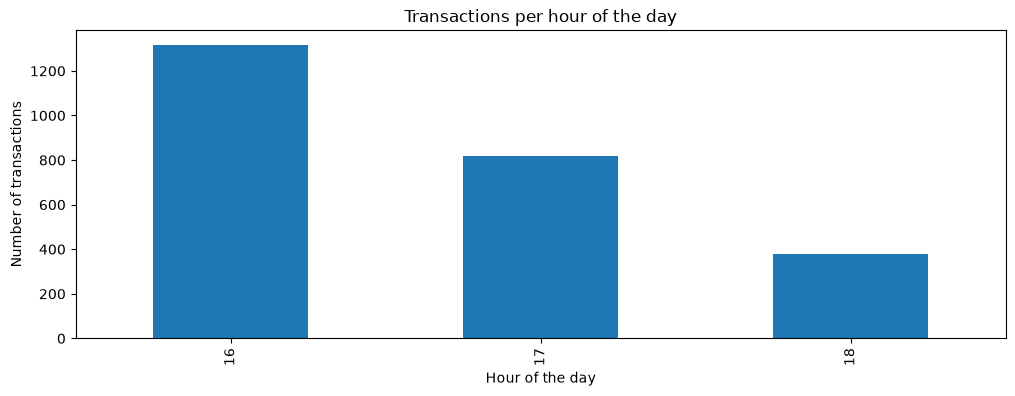

In [133]:
df["Hour"] = df["TransactionDate"].dt.hour
transactions_per_hour = df.groupby("Hour")["TransactionID"].count()
transactions_per_hour.plot(kind="bar", figsize=(12, 4))
plt.title("Transactions per hour of the day")
plt.xlabel("Hour of the day")
plt.ylabel("Number of transactions")
plt.show()

All transactions fall within three hours of the day: 16:00, 17:00 and 18:00. Because no other hours are present, the time of day cannot show unusual activity and is not useful for detecting anomalies.

In [134]:
df["Date"] = df["TransactionDate"].dt.date
per_account_per_day = df.groupby(["AccountID", "Date"])["TransactionID"].count()
print(per_account_per_day.sort_values(ascending=False).head(10))
print("Account-days with 2 or more transactions:", (per_account_per_day >= 2).sum())

AccountID  Date      
AC00362    2023-08-14    2
AC00284    2023-06-12    2
AC00110    2023-06-26    2
AC00459    2023-02-13    2
AC00279    2023-03-02    2
AC00153    2023-08-21    2
AC00177    2023-11-27    2
AC00295    2023-11-29    2
AC00292    2023-12-25    2
AC00313    2023-09-20    2
Name: TransactionID, dtype: int64
Account-days with 2 or more transactions: 37


In [135]:
df_sorted = df.sort_values(["AccountID", "TransactionDate"])
df_sorted["MinutesSincePrev"] = (
    df_sorted.groupby("AccountID")["TransactionDate"].diff().dt.total_seconds()/60
)
print("Transactions less than 60 minutes after the previous one:",
      (df_sorted["MinutesSincePrev"]<60).sum())

Transactions less than 60 minutes after the previous one: 16


No account made more than 2 transactions per day, and only 37 account-days had 2 transactions. There were also just 16 cases where the time between 2 transactions from the same account was less than 60 minutes. This means there are no real bursts of transactions in this dataset.

In [136]:
print(df["TransactionType"].value_counts())
print(df["Channel"].value_counts())
print(df["LoginAttempts"].value_counts())

TransactionType
Debit     1944
Credit     568
Name: count, dtype: int64
Channel
Branch    868
ATM       833
Online    811
Name: count, dtype: int64
LoginAttempts
1    2390
5      32
4      32
3      31
2      27
Name: count, dtype: int64


# Channels and Transaction Types

In [137]:
df.groupby("Channel")["TransactionAmount"].agg(["count", "median", "max"])

,count,median,max
Channel,,,
ATM,833,218.96,1919.11
Branch,868,204.16,1664.33
Online,811,206.63,1831.02


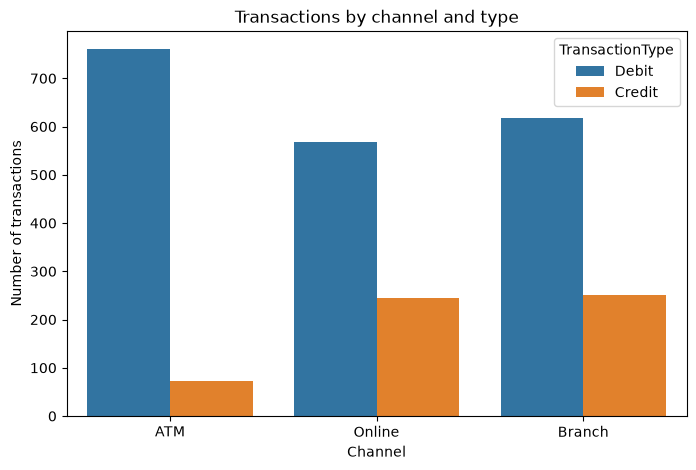

In [138]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Channel", hue="TransactionType")
plt.title("Transactions by channel and type")
plt.xlabel("Channel")
plt.ylabel("Number of transactions")
plt.show()

In [139]:
df.groupby("TransactionType")["TransactionAmount"].agg(["count", "median", "max"])

,count,median,max
TransactionType,,,
Credit,568,223.36,1831.02
Debit,1944,205.14,1919.11


Transactions are spread almost evenly across the three channels (ATM 833, Branch 868, Online 811). Debit transactions are much more common, with 1,944 compared to 568 credit transactions. Median amounts are similar across channels (204.16-218.96) and between transaction types (205.14 for debit, 223.36 for credit). There are no major differences that would suggest unusual activity.

# Variables Useful for Detecting Unusual Behaviour

In [140]:
df["MultipleLogins"] = df["LoginAttempts"]>1
df.groupby("MultipleLogins")[["TransactionAmount", "TransactionDuration", "AccountBalance"]].median()

,TransactionAmount,TransactionDuration,AccountBalance
MultipleLogins,,,
False,211.270,111.0,4732.69
True,203.625,127.5,4974.55


Only 122 transactions (about 4.9%) have more than one login attempt. These transactions do not differ much in amount (median 203.63 vs 211.27) or account balance (4,974.55 vs 4,732.69). However, the median transaction duration is longer (127.5 compared to 111.0 seconds). This makes multiple login attempts worth flagging, not because they are linked to larger amounts. Transaction amount is another useful indicator, as a small number of transactions have much higher values than the rest.

# Rules for Suspicious Transactions

In [141]:
amount_threshold = df["TransactionAmount"].quantile(0.95)
duration_threshold = df["TransactionDuration"].quantile(0.95)
df["Rule1_Logins"] = df["LoginAttempts"] >= 3
df["Rule2_BigAmount"] = df["TransactionAmount"] > amount_threshold
df["Rule3_LongDuration"] = df["TransactionDuration"] > duration_threshold
print("Amount threshold (top 5%):", round(amount_threshold, 2))
print("Duration threshold (top 5%):", round(duration_threshold, 2))
print("Rule 1 (3+ login attempts):", df["Rule1_Logins"].sum())
print("Rule 2 (top 5% amounts):", df["Rule2_BigAmount"].sum())
print("Rule 3 (top 5% durations):", df["Rule3_LongDuration"].sum())

Amount threshold (top 5%): 878.18
Duration threshold (top 5%): 265.0
Rule 1 (3+ login attempts): 95
Rule 2 (top 5% amounts): 126
Rule 3 (top 5% durations): 123


In [142]:
rule_columns = ["Rule1_Logins", "Rule2_BigAmount", "Rule3_LongDuration"]
df["RulesTriggered"] = df[rule_columns].sum(axis=1)
print(df["RulesTriggered"].value_counts().sort_index())

RulesTriggered
0    2182
1     316
2      14
Name: count, dtype: int64


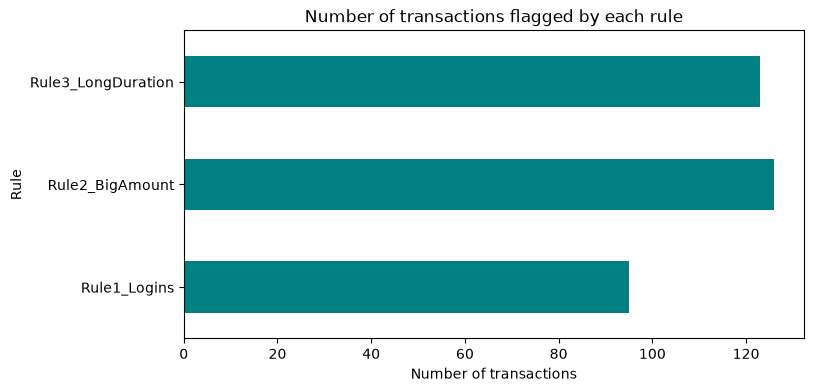

In [143]:
rule_counts = df[rule_columns].sum()
rule_counts.plot(kind="barh", figsize=(8, 4), color="teal")
plt.title("Number of transactions flagged by each rule")
plt.xlabel("Number of transactions")
plt.ylabel("Rule")
plt.show()

In [144]:
flagged = df[df["RulesTriggered"]>=2]
print("Transactions flagged by 2 or more rules:", len(flagged))
flagged[["TransactionID", "AccountID", "TransactionAmount",
         "TransactionDuration", "LoginAttempts"]]

Transactions flagged by 2 or more rules: 14


,TransactionID,AccountID,TransactionAmount,TransactionDuration,LoginAttempts
146,TX000147,AC00385,973.39,296,1
274,TX000275,AC00454,1176.28,174,5
375,TX000376,AC00316,1392.54,297,1
394,TX000395,AC00326,6.30,283,5
454,TX000455,AC00264,611.11,282,4
551,TX000552,AC00465,106.16,277,4
898,TX000899,AC00083,1531.31,62,4
1057,TX001058,AC00191,83.07,291,4
1213,TX001214,AC00170,1192.20,103,5
1447,TX001448,AC00080,991.82,300,1


I used three simple rules to identify unusual transactions: 3 or more login attempts (95 transactions), an amount above 878.18 (126 transactions) and a duration above 265 seconds (123 transactions). The last two thresholds are the top 5% of values chosen by me, so the number of flagged transactions was expected. Out of 2,512 transactions, 2,182 did not trigger any rule, 316 triggered one rule and 14 triggered two rules. The 14 transactions that triggered two rules are the most suspicious candidates, but without fraud labels it is not possible to measure how well these rules identify actual fraud.

# Conclusions
## Key findings
1. The median transaction amount is 211.14, while the median number of transactions per account is 5 for the year.
2. Four accounts made 12 transactions each. AC00460 and AC00363 also rank among the top 10 by both number and total amount of transactions.
3. All transactions were recorded within three hours of the day. Frequent transaction bursts were also uncommon, as no account made more than two transactions per day.
4. Transaction channels and types show similar median amounts, with values ranging from 204.16 to 218.96 across channels. No clear differences were found.
5. Only 122 transactions (about 4.9%) have multiple login attempts. Тhese transactions had a longer median duration (127.5 compared to 111.0 seconds), but their amounts were similar to the rest.
6. Three rules flagged 330 transactions, and 14 were flagged by two rules, making them the main candidates for further review.
## Limitations
* The dataset does not include fraud labels, so flagged transactions cannot be confirmed as fraudulent. It is also not possible to measure how accurately the rules detect fraud.
* PreviousTransactionDate is later than TransactionDate in all rows, so this column was excluded from the analysis.
* All transactions occurred between 16:00 and 18:00. Because no other hours are represented, transaction time cannot be used to detect unusual activity.
* Each account made only about 5 transactions during the year on average. This provides limited information about the usual behaviour of individual accounts.
* The rule thresholds were chosen by me rather than optimised or tested against confirmed fraud cases.